## This notebook provide the instructions on how to read the DYAMOND data from the SealStorage using OpenVisus framework.

# **Step 1: Importing the libraries**

In [1]:
import numpy as np
import OpenVisus as ov
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1 import make_axes_locatable

### The section below shows different LLC2160 fields we have available in cloud. 

### set the variable

In [2]:
variable='salt' # options are: u,v,w,salt,theta

In [3]:
# DONOT TOUCH
base_url= "https://nsdf-climate3-origin.nationalresearchplatform.org:50098/nasa/nsdf/climate3/dyamond/"
if variable=="theta" or variable=="w":
    base_dir=f"mit_output/llc2160_{variable}/llc2160_{variable}.idx"
elif variable=="u":
    base_dir= "mit_output/llc2160_arco/visus.idx"
else:
    base_dir=f"mit_output/llc2160_{variable}/{variable}_llc2160_x_y_depth.idx"


In [4]:
field= base_url+base_dir

## **Step 2: Reading the metadata file from cloud**
In this section, you can select any variables that you can declared in the cells above and replace it inside `LoadDataset`. We are just reading the metadata for the dataset here.

In [5]:
db=ov.LoadDataset(field)
print(f'Dimensions: {db.getLogicBox()[1][0]}*{db.getLogicBox()[1][1]}*{db.getLogicBox()[1][2]}')
print(f'Total Timesteps: {len(db.getTimesteps())}')
print(f'Field: {db.getField().name}')
print('Data Type: float32')

Dimensions: 8640*6480*90
Total Timesteps: 10366
Field: salt
Data Type: float32


## **Step 3:  Data Selection**
This section shows you how to load the data you want. You can select any timestep, region (x,y,z) you want. You can set the quality or resolution of the data as well. Higher quality means the finer(more) data. Not setting any time means first timestep available. Not setting quality means full data which takes a while to load because of the higher filesize. 

In [6]:
data=db.read(time=0,quality=-18,z=[0,1])
data.shape

(1, 102, 135)

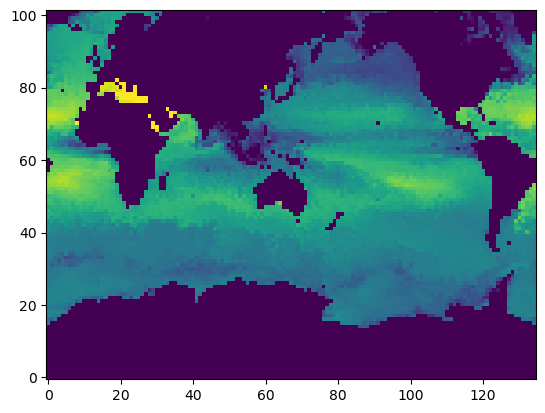

In [7]:
plt.imshow(data[0],origin='lower',vmin=31,vmax=38)

## **Step 4:  Visualize the data**
We are using a simple matplotlib here, but since the data is in numpy array, it can loaded with any python modules that support numpy. Feel free to set the `vmin`,`vmax` appropriately.

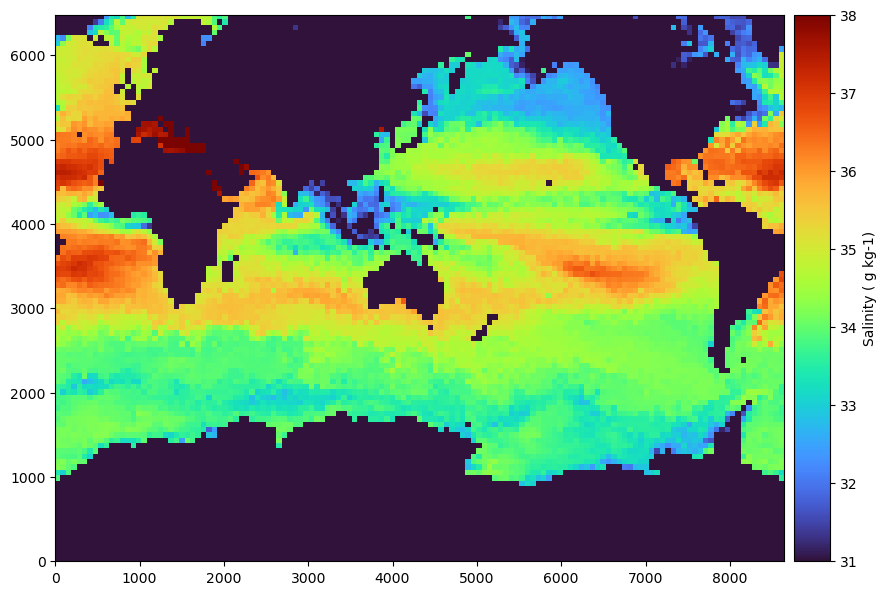

In [8]:
fig,axes=plt.subplots(1,1, figsize=(10,8))
axes.set_xlim(0,8640)
axes.set_ylim(0,6480)
im=axes.imshow(data[0,:,:],extent=[0,8640,0,6480],origin='lower',cmap='turbo',vmin=31,vmax=38)
divider = make_axes_locatable(axes)
cax = divider.append_axes("right",  size="5%", pad=0.1)  # Adjust size and pad as needed

cbar = plt.colorbar(im, cax=cax)
cbar.set_label('Salinity ( g kg-1)')
plt.show()

## **But, what if you want to see the full data for a certain region at a certain depth?**
Just set the right x,y,z while reading the data. x and y are the bounding box, z is the depth/layer. 

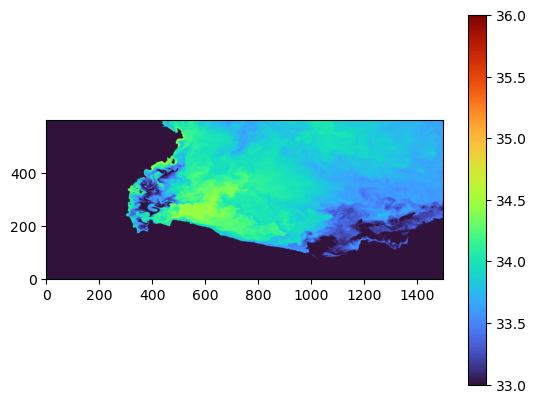

In [9]:
data1=db.read(time=0,z=[0,1],x=[4500,6000],y=[800,1400],quality=0)
plt.imshow(data1[0,:,:], origin='lower',vmin=33,vmax=36,cmap='turbo')
plt.colorbar()


# **Step 5: Save the data for the region locally**
You can save the data locally as you want. For example, here we are only saving the region shown above as a numpy array.

In [10]:
np.save('test_region1.npy', data1)

# **Step 6: Load the locally saved region and visualize using matplotlib**

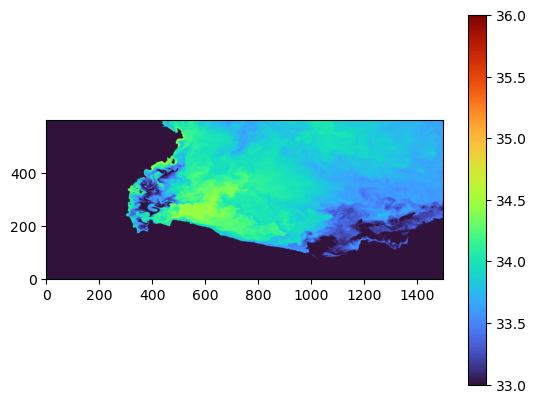

In [11]:
local_data=np.load('test_region1.npy')
plt.imshow(local_data[0,:,:], origin='lower',vmin=33,vmax=36,cmap='turbo')
plt.colorbar()

## Lexy's Work

I will be attempting to:
1. Perform PDA </br>
    a. see what variables are available in this dataset </br>
    b. see what times are available </br>
2. assign labels to data
    a. variables
    b. time / dates
3. focus in on pre-determined lat and long
4. train model
5. predict with validation data

### 1a. Available variables

In [12]:
print(db.getFields())       # list fields

['salt']


The available variables are:
- salt:     Salinity — salt concentration in seawaterPSU (practical salinity units)
- u:        East-West velocity — horizontal current (zonal)m/s
- v:        North-South velocity — horizontal current (meridional)m/s
- w:        Vertical velocity — upward/downward water movementm/s
- theta:    Potential temperature — ocean water temperature°C

Which is consistent with the website information: https://sciviscontest2026.github.io/data/home#data2

### 1b. Available Times

In [13]:
print(max(db.getTimesteps()))    # list available timesteps too

10365


### 2. Assign Labels

In [14]:
import pandas as pd
import numpy as np
import datetime

In [15]:
# Confirmed: full grid is [0,0,0] to [8640, 6480, 90]
# So the mapping is:
# x: 0→8640 = 0°→360° longitude (NOT -180 to 180!)
# y: 0→6480 = -90°→90° latitude

# That explains the global plot — longitude starts at 0° (Greenwich), goes EAST
# Atlantic in 0-360 space is roughly lon: 280→360 (west) and 0→20 (east)

# Convert Atlantic lat/lon bounds to pixel indices
def lon_to_x(lon_deg, total_x=8640):
    """Convert longitude (-180 to 180 or 0 to 360) to pixel index"""
    if lon_deg < 0:
        lon_deg += 360   # convert -80 → 280, etc.
    return int(lon_deg / 360 * total_x)

def lat_to_y(lat_deg, total_y=6480):
    """Convert latitude (-90 to 90) to pixel index"""
    return int((lat_deg + 90) / 180 * total_y)

# Atlantic bounds
x_west = lon_to_x(-90) 
x_east = lon_to_x(20)   
y_south = lat_to_y(5)  
y_north = lat_to_y(55) 

print(f"Atlantic pixels — x: {x_west}→8640 and 0→{x_east}, y: {y_south}→{y_north}")

Atlantic pixels — x: 6480→8640 and 0→480, y: 3420→5220


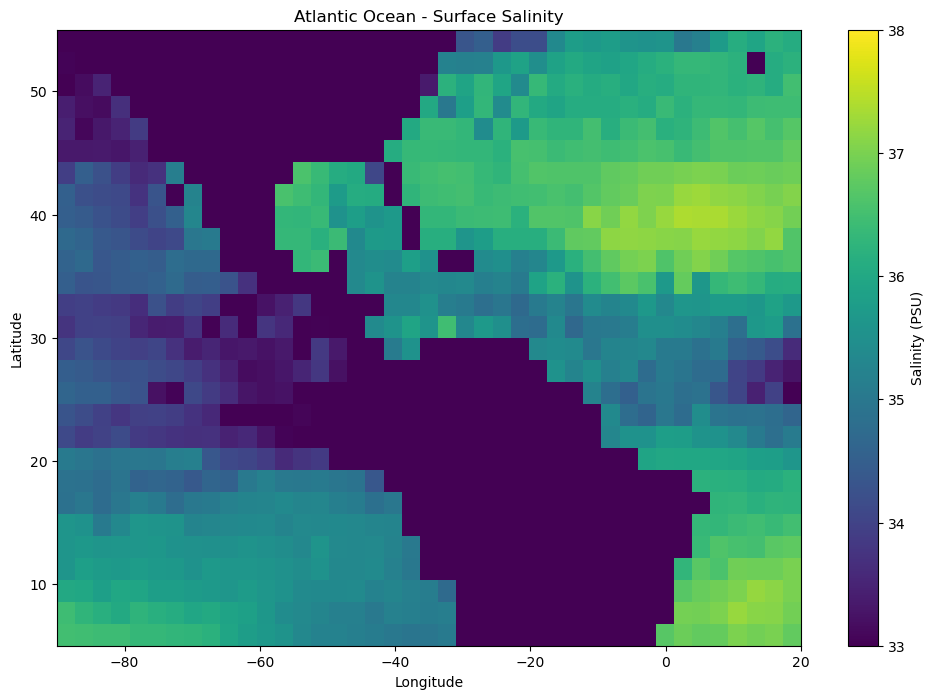

In [16]:
# At quality=-18, scale factor ≈ 8640/135 = 64
scale = 8640 / 135  # ~64

# Scaled pixel coords
x_west_s  = int(x_west  / scale)  # ~105
x_east_s  = int(x_east  / scale)  # ~7
y_south_s = int(y_south / scale)  # ~17
y_north_s = int(y_north / scale)  # ~90

salt_raw = data[0]
# salt_clean = np.where(salt_raw > 1, salt_raw, np.nan)

# Atlantic spans the wrap-around (280°→360° + 0°→20°)
# So read two chunks and hstack
atlantic_west = salt_raw[y_south_s:y_north_s, x_west_s:]   # 280°→360°
atlantic_east = salt_raw[y_south_s:y_north_s, :x_east_s]   # 0°→20°

salt_atlantic = np.hstack([atlantic_west, atlantic_east])

plt.figure(figsize=(12, 8))
plt.imshow(salt_atlantic, origin='lower', vmin=33, vmax=38, aspect='auto', 
           extent = [-90, 20, 5, 55]
)
plt.colorbar(label='Salinity (PSU)')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.title('Atlantic Ocean - Surface Salinity')
plt.show()

In [17]:
# First, just check what you actually have
print("salt_atlantic shape:", salt_atlantic.shape)
print("atlantic_west shape:", atlantic_west.shape)
print("atlantic_east shape:", atlantic_east.shape)
print()
print("x_west_s:", x_west_s)
print("x_east_s:", x_east_s)
print("y_south_s:", y_south_s)
print("y_north_s:", y_north_s)

salt_atlantic shape: (28, 41)
atlantic_west shape: (28, 34)
atlantic_east shape: (28, 7)

x_west_s: 101
x_east_s: 7
y_south_s: 53
y_north_s: 81


changing labels

In [18]:
start_date = datetime.datetime(2020, 1, 20)
timesteps = range(0, max(db.getTimesteps()) + 1) 

In [19]:
# read all timesteps into a list
records = []
for t in timesteps:
    data = db.read(time=t, quality=-18, z=[0, 1])
    
    # Flatten the 2D spatial slice into a mean (or keep raw values)
    salt_mean = float(np.nanmean(data[0]))  # single summary value per timestep
    
    # Convert timestep → readable datetime
    timestamp = start_date + datetime.timedelta(hours=t)
    label = timestamp.strftime("%m/%d/%Y-%H")  # e.g. "01/20/2020-00"
    
    records.append({"time": label, "salt": salt_mean})

KeyboardInterrupt: 

In [ ]:

df = pd.DataFrame(records)
df = df.set_index("time")
print(df.head())